# Concrete QC project - Step 1a (data understanding)

Goal: get to know the three files - what is in them, how much, and what looks strange.
We only LOOK at the data here. We do not fix or remove anything yet (that is Step 1b).
Run one cell at a time and write down anything that surprises you.

### Step 1: Load the files

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project = Path.cwd().parent   # the notebook runs from the notebooks folder, so the project is one level up

raw = project / "data" / "raw"

cubes = pd.read_csv(raw / "cube_results.csv")
mixes = pd.read_csv(raw / "mix_designs.csv")
durability = pd.read_csv(raw / "durability_results.csv")

print("Cubes:", cubes.shape)
print("Mixes:", mixes.shape)
print("Durability:", durability.shape)

Cubes: (4079, 31)
Mixes: (12, 16)
Durability: (198, 29)


## PART A - CUBE RESULTS (the main file)

### Step 2: What columns do we have?

Every row is ONE cube set (3 cubes) tested at one age.
The first columns (cement to fine_agg) come from the mix design, the rest from the lab report.

In [2]:
print(cubes.dtypes)

cement                    float64
slag                        int64
fly_ash                   float64
water                       int64
superplasticizer          float64
coarse_agg                  int64
fine_agg                    int64
design_slump_min            int64
design_slump_max            int64
measured_slump            float64
density                   float64
age                         int64
strength                  float64
mix_id                     object
match                      object
flag                       object
date_cast                  object
lr                         object
swl                        object
spec                       object
supplier_report            object
element                    object
folder                     object
specified_slump_report     object
slump_check                object
cube1                     float64
cube2                     float64
cube3                     float64
density1                  float64
density2      

### Step 3: Missing values

How many empty cells does each column have?

In [3]:
missing = cubes.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_table = pd.DataFrame({"Missing": missing, "Percent": (missing / len(cubes) * 100).round(1)})
print(missing_table)

                Missing  Percent
flag               3560     87.3
swl                 555     13.6
date_cast            73      1.8
measured_slump       58      1.4
slump_check          58      1.4
density3             54      1.3
cube3                40      1.0
density              14      0.3
density1             14      0.3
density2             14      0.3
lr                    4      0.1


Note: "flag" is empty when there is NO problem, so many blanks there is good news.

### Step 4: How many results per mix?

In [4]:
print(cubes["mix_id"].value_counts())

mix_id
AFR-30/20        1068
AFR-W40/20        789
AFR-20/20         505
AFR-40/20         421
AFR-25/20         320
AFR-15/20         312
AFR-W50/20        258
AFR-35/28CRCP     173
AFR-W30/20         79
AFR-W50/14         64
AFR-35/20          55
AFR-W50/20HS       35
Name: count, dtype: int64


### Step 5: At what ages were the cubes tested?

Most should be 7 and 28 days. Anything else is a late or special test.

In [5]:
print(cubes["age"].value_counts().sort_index())

age
7      2085
8        27
10        1
11        1
14        2
28     1879
29       21
31        1
32        3
34        4
36        8
40        1
41        3
42        2
43        1
46        1
47        1
48        8
50        7
53        1
54       10
55        1
56        4
69        1
75        1
77        1
120       3
180       1
Name: count, dtype: int64


### Step 6: The numbers - quick summary

Look at min and max: do they make sense for concrete?

In [6]:
number_columns = ["strength", "measured_slump", "density", "cube1", "cube2", "cube3"]
print(cubes[number_columns].describe().round(1))

       strength  measured_slump  density   cube1   cube2   cube3
count    4079.0          4021.0   4065.0  4079.0  4079.0  4039.0
mean       38.7           115.1   2388.6    38.7    38.9    38.4
std        13.1            51.4     34.7    13.6    13.2    13.0
min         2.7             0.0   1933.0     2.9     2.7     2.6
25%        29.5           105.0   2371.0    29.5    29.6    29.3
50%        39.0           125.0   2389.0    39.1    39.3    38.7
75%        47.7           145.0   2408.0    47.9    48.1    47.4
max       149.8           250.0   2507.0   272.5   150.0   149.5


### Step 7: Strength - first picture

Histogram of all 28-day results. We expect most between about 20 and 70 MPa.

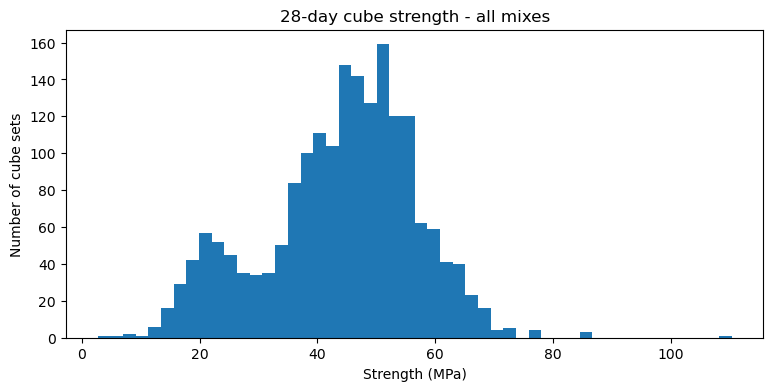

In [7]:
day28 = cubes[cubes["age"] == 28]

plt.figure(figsize=(9, 4))
plt.hist(day28["strength"], bins=50)
plt.title("28-day cube strength - all mixes")
plt.xlabel("Strength (MPa)")
plt.ylabel("Number of cube sets")
plt.show()

### Step 8: Slump - first picture

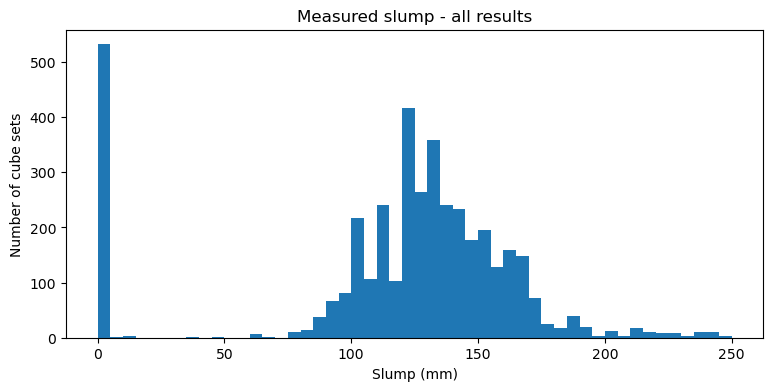

In [8]:
plt.figure(figsize=(9, 4))
plt.hist(cubes["measured_slump"].dropna(), bins=50)
plt.title("Measured slump - all results")
plt.xlabel("Slump (mm)")
plt.ylabel("Number of cube sets")
plt.show()

Notice the big bar near 0 mm. Those are the kerb results (dry extruded mix).

### Step 9: Density - first picture

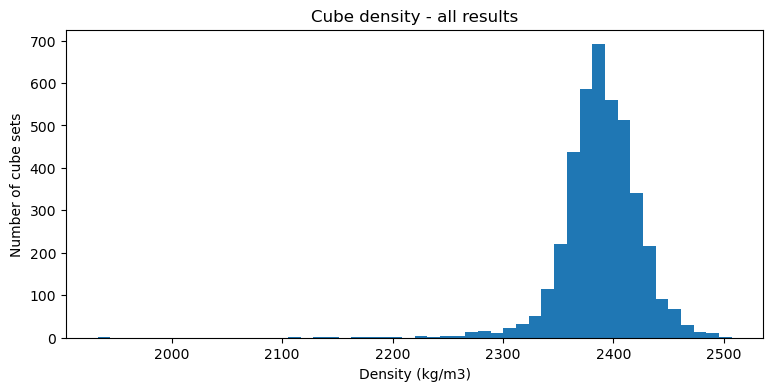

In [9]:
plt.figure(figsize=(9, 4))
plt.hist(cubes["density"].dropna(), bins=50)
plt.title("Cube density - all results")
plt.xlabel("Density (kg/m3)")
plt.ylabel("Number of cube sets")
plt.show()

### Step 10: The quality columns we built

match = how sure we are about the mix design for that result
flag = rows we already know have a problem
slump_check = measured slump compared with the design range

In [10]:
print(cubes["match"].value_counts())
print()
print(cubes["flag"].value_counts())
print()
print(cubes["slump_check"].value_counts())

match
exact                      3081
class only                  821
element (CRCP pavement)     173
description (25MPa/20)        4
Name: count, dtype: int64

flag
kerb mix (near-zero slump) - may not be the D2 mix                                     514
cube spread > 30%                                                                        2
strength > 100 MPa - check; kerb mix (near-zero slump) - may not be the D2 mix           1
kerb mix (near-zero slump) - may not be the D2 mix; density outside 2100-2600 kg/m3      1
strength > 100 MPa - check; cube spread > 30%                                            1
Name: count, dtype: int64

slump_check
within    2281
above     1181
below      559
Name: count, dtype: int64


### Step 11: Where was the concrete used?

The folder column tells us the structure and element. Show the 15 most common.

In [11]:
print(cubes["folder"].value_counts().head(15))

folder
04_Miscellaneous Concrete/Kerbs & Channels                   624
04_Miscellaneous Concrete/Stormwater Structures              443
04_Miscellaneous Concrete/Duct Encasement & Thrust Blocks    336
03_Structures/Ramp A/Parapets                                311
03_Structures/Ramp B/Parapets                                254
01_Road Layers/06_CRCP Concrete Pavement                     210
03_Structures/Ramp C/Parapets                                193
04_Miscellaneous Concrete/Other Concrete                     192
03_Structures/Ramp D/Parapets                                147
03_Structures/Ramp B/MSE Walls (raft, upstands, panels)      146
03_Structures/Ramp D/MSE Walls (raft, upstands, panels)      145
04_Miscellaneous Concrete/Sidewalks, Paving & Slabs          102
03_Structures/Hanover Park Bus Station/Retaining Walls        76
03_Structures/Ramp D/Piers                                    66
03_Structures/Ramp B/Piers                                    60
Name: count, dtype

### Step 12: Dates

In [12]:
cubes["date_cast"] = pd.to_datetime(cubes["date_cast"], errors="coerce")
print("First cast date:", cubes["date_cast"].min())
print("Last cast date:", cubes["date_cast"].max())
print("Rows with no cast date:", cubes["date_cast"].isna().sum())

# Results per year
print(cubes["date_cast"].dt.year.value_counts().sort_index())

First cast date: 2022-12-07 00:00:00
Last cast date: 2026-09-18 00:00:00
Rows with no cast date: 73
date_cast
2022.0       4
2023.0     186
2024.0     616
2025.0    1494
2026.0    1706
Name: count, dtype: int64


## PART B - MIX DESIGNS

### Step 13: The 12 approved mixes

Every cube result above got its cement, fly ash, water etc. from one of these rows.

In [13]:
print(mixes[["mix_id", "cement", "fly_ash", "water", "admixture_l", "coarse_agg", "fine_agg",
             "design_slump_min", "design_slump_max", "target"]])

           mix_id  cement  fly_ash  water  admixture_l  coarse_agg  fine_agg  \
0       AFR-15/20   120.0     51.0    180        1.026        1010      1011   
1       AFR-20/20   152.0     65.0    178        1.302        1030       956   
2       AFR-25/20   178.0     76.0    170        1.397        1031       931   
3       AFR-30/20   195.0     84.0    168        1.674        1070       913   
4       AFR-35/20   202.0     87.0    168        1.734        1100       851   
5       AFR-40/20   239.0    102.0    167        2.046        1080       856   
6      AFR-W30/20   236.0    101.0    185        2.019         890       970   
7      AFR-W40/20   284.0    122.0    178        2.436         937       866   
8      AFR-W50/20   299.0    128.0    178        2.562         951       847   
9      AFR-W50/14   303.8    130.2    178        3.472         850       923   
10   AFR-W50/20HS   302.0    130.0    178        5.184         951       821   
11  AFR-35/28CRCP   320.0      0.0    17

### Step 14: Water / binder ratio

Binder = cement + fly ash. A lower water/binder ratio usually means stronger, denser concrete.

In [14]:
mixes["binder"] = mixes["cement"] + mixes["fly_ash"]
mixes["water_binder"] = (mixes["water"] / mixes["binder"]).round(2)
mixes["fly_ash_percent"] = (mixes["fly_ash"] / mixes["binder"] * 100).round(0)
print(mixes[["mix_id", "binder", "water_binder", "fly_ash_percent"]])

           mix_id  binder  water_binder  fly_ash_percent
0       AFR-15/20   171.0          1.05             30.0
1       AFR-20/20   217.0          0.82             30.0
2       AFR-25/20   254.0          0.67             30.0
3       AFR-30/20   279.0          0.60             30.0
4       AFR-35/20   289.0          0.58             30.0
5       AFR-40/20   341.0          0.49             30.0
6      AFR-W30/20   337.0          0.55             30.0
7      AFR-W40/20   406.0          0.44             30.0
8      AFR-W50/20   427.0          0.42             30.0
9      AFR-W50/14   434.0          0.41             30.0
10   AFR-W50/20HS   432.0          0.41             30.0
11  AFR-35/28CRCP   320.0          0.53              0.0


Notice: every mix has about 30% fly ash, except the CRCP (0%).

## PART C - DURABILITY RESULTS

### Step 15: What is in the durability file?

One row per durability test (a test panel), mostly from bridge elements.

In [15]:
print(durability.dtypes)

lr                            object
swl                           object
panel                        float64
structure                     object
element_type                  object
element                       object
date_cast                     object
age_days                       int64
opi_1                        float64
opi_2                        float64
opi_3                        float64
opi_4                        float64
opi_mean                     float64
opi_cov                        int64
opi_judgement                 object
sorp_1                       float64
sorp_2                       float64
sorp_3                       float64
sorp_4                       float64
sorptivity_mean              float64
sorp_judgement                object
porosity                     float64
chloride_cond                float64
chloride_reported_suspect    float64
overall                       object
flags                         object
report_date                   object
s

### Step 16: Missing values

In [16]:
missing = durability.isna().sum()
print(missing[missing > 0].sort_values(ascending=False))

chloride_cond                185
chloride_reported_suspect     83
flags                         51
panel                         33
swl                            3
sorp_1                         1
sorp_2                         1
sorp_3                         1
sorp_4                         1
sorptivity_mean                1
sorp_judgement                 1
porosity                       1
dtype: int64


### Step 17: Where were the tests done?

In [17]:
print(durability["structure"].value_counts())
print()
print(durability["element_type"].value_counts())

structure
Ramp A                       49
Ramp D                       49
Ramp B                       36
Sky Circle                   26
Ramp C                       19
WB Retaining Wall SV1+200    13
Culvert                       3
EB IVC Wall                   2
Design check                  1
Name: count, dtype: int64

element_type
Pier                    82
Deck                    42
Wall                    25
Parapet                 14
Deck (Sky Circle)       14
Pile cap                 9
Abutment                 5
Culvert                  3
Other                    3
Design check / trial     1
Name: count, dtype: int64


### Step 18: The three durability tests - quick summary

OPI must be above 9.3 and sorptivity below 10 (contract spec, Table B6404/4)

In [18]:
print(durability[["opi_mean", "sorptivity_mean", "porosity", "chloride_cond", "age_days"]].describe().round(2))

       opi_mean  sorptivity_mean  porosity  chloride_cond  age_days
count    198.00           197.00    197.00          13.00    198.00
mean      10.32             6.66      7.66           0.36     62.53
std        0.38             0.83      5.65           0.08     22.73
min        9.45             4.77    -45.60           0.20      0.00
25%       10.08             6.04      7.20           0.31     46.00
50%       10.30             6.53      8.10           0.36     58.00
75%       10.54             7.29      9.10           0.43     81.75
max       11.43             8.85     14.00           0.49    148.00


### Step 19: The data problems we already found

In [19]:
print(durability["flags"].value_counts())

flags
chloride disk values identical on 115 reports (0.299/0.377/0.426/0.288) - likely copied from another report, query SWL                                                                                                                                            56
OPI variability high (COV 33%)                                                                                                                                                                                                                                     6
chloride disk values identical on 115 reports (0.299/0.377/0.426/0.288) - likely copied from another report, query SWL; OPI variability high (COV 46%)                                                                                                             4
chloride disk values identical on 115 reports (0.299/0.377/0.426/0.288) - likely copied from another report, query SWL; OPI variability high (COV 32%)                                                             

The chloride values: 115 reports show exactly the same four numbers, so they look copied.
We keep them in a separate column (chloride_reported_suspect) and will not use them.

### Step 20: Write down what you learned

Answer these in your own words before Step 1b:
1. How many cube results do we have, and for how many mixes?
2. Which columns have the most missing values, and does it matter?
3. What looks wrong or strange in the strength, slump or density pictures?
4. Which rows will we probably need to remove or treat separately in Step 1b?